<table class="table table-bordered">
    <tr>
        <th style="text-align:center;"><h1>Deep Learning</h1><h2>Assignment (Problem 2) - Sentiment Analysis Model (Individual + Group)</h2><h3>AY2026/27 Semester</h3></th>
    </tr>
</table>

<h3>Name: Jaether</h3>

In [44]:
# Import the Required Packages
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

import re

import keras
from keras import layers, Model
from keras.models import Sequential
from keras.layers import TextVectorization, Embedding, LSTM, Dense, Input, Conv1D, GlobalAveragePooling1D, Dropout
from keras.regularizers import l2
from keras.optimizers import Adam
from keras.utils import to_categorical
from sklearn.metrics import classification_report
from keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split

Function for plotting train and validation curves.

In [2]:
def plot_curves(history, title=''):
    h = history.history if hasattr(history, 'history') else history
    acc, val_acc = h['acc'], h['val_acc']
    loss, val_loss = h['loss'], h['val_loss']
    epochs = range(1, len(acc)+1)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,4))

    ax1.plot(epochs, acc, 'bo', label='Training acc')
    ax1.plot(epochs, val_acc, 'b', label='Validation acc')
    ax1.set_title(f'Training and validation accuracy ({title})')
    ax1.legend()

    ax2.plot(epochs, loss, 'bo', label='Training loss')
    ax2.plot(epochs, val_loss, 'b', label='Validation loss')
    ax2.set_title(f'Training and validation loss ({title})')
    ax2.legend()
    
    plt.tight_layout()
    plt.show()

## Step 1 – Data Loading and Processing

### 1.1 Data Loading

In [3]:
df = pd.read_csv(r"TikTok_reviews.csv")
df.head()

,content,score
0,i don't know how to update,2
1,My favorite app😊,5
2,just entertainment,5
3,good,5
4,good👍,5


Creating a balanced dataset 

In [4]:
# Dropping null values from dataset
df = df.dropna(subset=['content', 'score'])


min_class_count = df['score'].value_counts().min()
cap_multiplier = 3  

balanced_parts = []
for score in sorted(df['score'].unique()):
    subset = df[df['score'] == score]
    n = min(len(subset), int(min_class_count * cap_multiplier))  # won't exceed what's available
    balanced_parts.append(subset.sample(n=n, random_state=42))

df_balanced = pd.concat(balanced_parts).sample(frac=1, random_state=42).reset_index(drop=True)
df_balanced['score'].value_counts()

score
5    16047
1    16047
4     6693
3     6304
2     5349
Name: count, dtype: int64

### 1.2 Data Processing


In [5]:
def clean(text):
    text = text.lower()
    text = text.replace("’", "'")  #cause iphone keyboards use that weird curly apostrophe 
    text = re.sub(r"[^a-z\s']", ' ', text)  #keep letters only
    text = re.sub(r"\s+", ' ', text)
    text = text.strip()
    return text

df_balanced = df_balanced.dropna(subset=['content']).reset_index(drop=True)
df_balanced['clean_content'] = df_balanced['content'].astype(str).apply(clean)
df_balanced.head()

,content,score,clean_content
0,♥️♥️♥️,5,
1,no love,1,no love
2,Chrash!!!,1,chrash
3,okay,3,okay
4,Apk yang bagus🗿👍,5,apk yang bagus


Dataset contains some non-English reviews (noise). Left as they are to keep a realistic dataset because reviews are naturally multillingual.

In [6]:
# Convert the content and scores into numeric tensors
maxlen = 100
max_words = 10000

texts = df_balanced['clean_content'].astype(str).to_list()
scores = df_balanced['score'].values

vectorizer = keras.layers.TextVectorization(
    max_tokens=max_words,
    output_mode='int',
    output_sequence_length=maxlen
)
vectorizer.adapt(texts)

X = vectorizer(texts)
X = np.array(X)

vocab = vectorizer.get_vocabulary()
word_index = {word: index for index, word in enumerate(vocab)}
print(f'Found {len(word_index)} unique tokens.')

y = to_categorical(scores - 1, num_classes=5)

print(f'X shape: {X.shape}')
print(f'y shape: {y.shape}')

Found 10000 unique tokens.
X shape: (50440, 100)
y shape: (50440, 5)


### 1.3 Data Sampling

In [7]:
# Split the X & y into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y)  
#added stratify to make sure that an even mix of all classes are present
print(f'shape of train sets: X {X_train.shape}, y {y_train.shape}')
print(f'shape of test sets: X {X_test.shape}, y {y_test.shape}')

shape of train sets: X (40352, 100), y (40352, 5)
shape of test sets: X (10088, 100), y (10088, 5)


## Step 2 – Develop a Sentiment Analysis Model

Word Embedding (GloVe)

In [8]:
# Load GloVe
glove_dir = r'C:\Users\jaeth\Downloads\NP\Y2S1\DL\pracs\glove.6B\glove.6B'
embeddings_index = {}

f = open(os.path.join(glove_dir, 'glove.6B.200d.txt'), encoding='utf8')
for line in f:
    values = line.split()
    word = values[0]
    coefs = np.asarray(values[1:], dtype='float32')
    embeddings_index[word] = coefs
f.close()

print(f'found {len(embeddings_index)} word vectors.')

found 400001 word vectors.


In [9]:
# Build embedding matrix from word_index
embedding_dim = 200

embedding_matrix = np.zeros((max_words, embedding_dim))
for word, i in word_index.items():
    if i < max_words:
        embedding_vector = embeddings_index.get(word)
        if embedding_vector is not None:
            embedding_matrix[i] = embedding_vector
            #words not found in embedding index will be all-zeros
            
embedding_matrix.shape

(10000, 200)

### Model #1 (from scratch)

In [10]:
# Build the Model
model2 = Sequential()
model2.add(Input(shape=(maxlen,)))
model2.add(Embedding(max_words, 32))
model2.add(Conv1D(32, 7, activation='relu'))
model2.add(GlobalAveragePooling1D())
model2.add(Dense(5, activation='softmax'))

In [11]:
# Train the Model
model2.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['acc'])
model2.summary()
hist2 = model2.fit(X_train, y_train, epochs=10, batch_size=32, validation_split=0.3)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 94, 32)         │         7,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 327,365 (1.25 MB)

 Trainable params: 327,365 (1.25 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
883/883 ━━━━━━━━━━━━━━━━━━━━ 14s 12ms/step - acc: 0.4719 - loss: 1.3648 - val_acc: 0.5344 - val_loss: 1.2486
Epoch 2/10
883/883 ━━━━━━━━━━━━━━━━━━━━ 21s 12ms/step - acc: 0.5615 - loss: 1.1969 - val_acc: 0.5731 - val_loss: 1.1699
Epoch 3/10
883/883 ━━━━━━━━━━━━━━━━━━━━ 20s 12ms/step - acc: 0.5859 - loss: 1.1316 - val_acc: 0.5848 - val_loss: 1.1601
Epoch 4/10
883/883 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - acc: 0.6028 - loss: 1.0911 - val_acc: 0.5864 - val_loss: 1.1486
Epoch 5/10
883/883 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - acc: 0.6140 - loss: 1.0594 - val_acc: 0.5866 - val_loss: 1.1518
Epoch 6/10
883/883 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - acc: 0.6238 - loss: 1.0317 - val_acc: 0.5861 - val_loss: 1.1623
Epoch 7/10
883/883 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - acc: 0.6324 - loss: 1.0074 - val_acc: 0.5792 - val_loss: 1.1788
Epoch 8/10
883/883 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - acc: 0.6408 - loss: 0.9846 - val_acc: 0.5802 - val_loss: 1.1950
Epoch 9/10
883/883 ━━━━━━━━━━━━━━━━━━━━ 

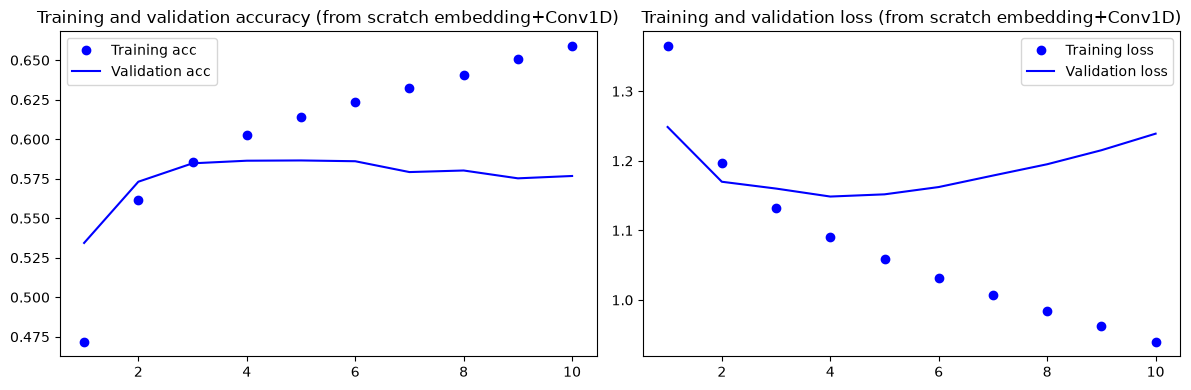

In [12]:
# Plot the Training and Validation Accuracy & Loss Scores
plot_curves(hist2, 'from scratch embedding+Conv1D')

In [51]:
y_pred = np.argmax(model2.predict(X_test), axis=1)
y_true = np.argmax(y_test, axis=1)  #convert one-hot y_test back to integer labels for classification report
print("Model 1 - Baseline Model")
print(classification_report(y_true, y_pred, target_names=[f'{i+1} star' for i in range(5)]))

316/316 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step
Model 1 - Baseline Model
              precision    recall  f1-score   support

      1 star       0.55      0.89      0.68      3209
      2 star       0.00      0.00      0.00      1070
      3 star       0.35      0.08      0.13      1261
      4 star       0.41      0.11      0.17      1339
      5 star       0.67      0.89      0.77      3209

    accuracy                           0.59     10088
   macro avg       0.40      0.39      0.35     10088
weighted avg       0.49      0.59      0.50     10088



c:\Users\jaeth\anaconda3\envs\hw\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\jaeth\anaconda3\envs\hw\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\jaeth\anaconda3\envs\hw\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


## Regularising Attempts:
### Model 1 - Attempt 1: Conv1D + Dropout + L2

In [13]:
model2b = Sequential()
model2b.add(Input(shape=(maxlen,)))
model2b.add(Embedding(max_words, 32))
model2b.add(Dropout(0.3))
model2b.add(Conv1D(16, 5, kernel_regularizer=l2(0.001), activation='relu'))
model2b.add(GlobalAveragePooling1D())
model2b.add(Dropout(0.5))
model2b.add(Dense(5, activation='softmax'))

In [14]:
model2b.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['acc'])
model2b.summary()
hist2b = model2b.fit(X_train, y_train, epochs=10, batch_size=32, validation_split=0.3)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 100, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 96, 16)         │         2,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_1      │ (None, 16)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │            85 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 322,661 (1.23 MB)

 Trainable params: 322,661 (1.23 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
883/883 ━━━━━━━━━━━━━━━━━━━━ 15s 13ms/step - acc: 0.4176 - loss: 1.4764 - val_acc: 0.4990 - val_loss: 1.3816
Epoch 2/10
883/883 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - acc: 0.4964 - loss: 1.3818 - val_acc: 0.5292 - val_loss: 1.3279
Epoch 3/10
883/883 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - acc: 0.5159 - loss: 1.3432 - val_acc: 0.5480 - val_loss: 1.2929
Epoch 4/10
883/883 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - acc: 0.5335 - loss: 1.3048 - val_acc: 0.5581 - val_loss: 1.2575
Epoch 5/10
883/883 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - acc: 0.5440 - loss: 1.2811 - val_acc: 0.5665 - val_loss: 1.2403
Epoch 6/10
883/883 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - acc: 0.5523 - loss: 1.2627 - val_acc: 0.5698 - val_loss: 1.2253
Epoch 7/10
883/883 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - acc: 0.5575 - loss: 1.2455 - val_acc: 0.5767 - val_loss: 1.2179
Epoch 8/10
883/883 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - acc: 0.5634 - loss: 1.2336 - val_acc: 0.5788 - val_loss: 1.2097
Epoch 9/10
883/883 ━━━━━━━━━━━━━━━━━━━━ 

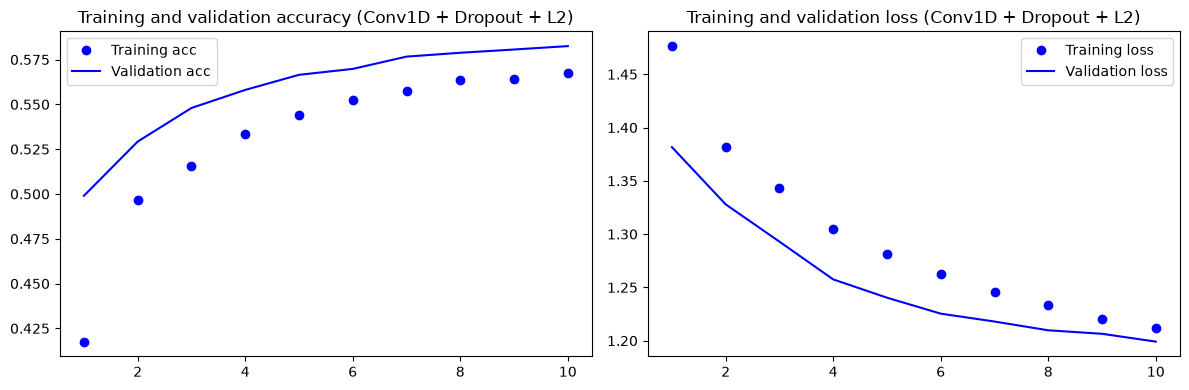

In [15]:
plot_curves(hist2b, 'Conv1D + Dropout + L2')

In [52]:
y_pred = np.argmax(model2b.predict(X_test), axis=1)
print("Model 1 - Attempt 1")
print(classification_report(y_true, y_pred, target_names=[f'{i+1} star' for i in range(5)]))

316/316 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Model 1 - Attempt 1
              precision    recall  f1-score   support

      1 star       0.55      0.86      0.67      3209
      2 star       0.25      0.00      0.00      1070
      3 star       0.37      0.04      0.08      1261
      4 star       0.36      0.07      0.12      1339
      5 star       0.63      0.91      0.75      3209

    accuracy                           0.58     10088
   macro avg       0.43      0.38      0.32     10088
weighted avg       0.50      0.58      0.48     10088



### Model 1 - Attempt 2: more regularisation (Dropout, L2) + EarlyStopping

In [16]:
model2c = Sequential()
model2c.add(Input(shape=(maxlen,)))
model2c.add(Embedding(max_words, 16))  #smaller embedding dimension too
model2c.add(Dropout(0.5))
model2c.add(Conv1D(8, 5, kernel_regularizer=l2(0.005), activation='relu'))  #even lesser filters + stronger L2
model2c.add(GlobalAveragePooling1D())
model2c.add(Dropout(0.6))
model2c.add(Dense(5, activation='softmax'))

In [17]:
model2c.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['acc'])
model2c.summary()

early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

hist2c = model2c.fit(X_train, y_train, epochs=20, batch_size=32, validation_split=0.3, callbacks=[early_stop])

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 100, 16)        │       160,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 100, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 96, 8)          │           648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_2      │ (None, 8)              │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │            45 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 160,693 (627.71 KB)

 Trainable params: 160,693 (627.71 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
883/883 ━━━━━━━━━━━━━━━━━━━━ 11s 10ms/step - acc: 0.3935 - loss: 1.5047 - val_acc: 0.4881 - val_loss: 1.4187
Epoch 2/20
883/883 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - acc: 0.4692 - loss: 1.4252 - val_acc: 0.5117 - val_loss: 1.3737
Epoch 3/20
883/883 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - acc: 0.4829 - loss: 1.3923 - val_acc: 0.5127 - val_loss: 1.3455
Epoch 4/20
883/883 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - acc: 0.4906 - loss: 1.3777 - val_acc: 0.5206 - val_loss: 1.3314
Epoch 5/20
883/883 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - acc: 0.4987 - loss: 1.3630 - val_acc: 0.5268 - val_loss: 1.3193
Epoch 6/20
883/883 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - acc: 0.5018 - loss: 1.3537 - val_acc: 0.5350 - val_loss: 1.3128
Epoch 7/20
883/883 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - acc: 0.5046 - loss: 1.3489 - val_acc: 0.5374 - val_loss: 1.3080
Epoch 8/20
883/883 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - acc: 0.5097 - loss: 1.3411 - val_acc: 0.5402 - val_loss: 1.3003
Epoch 9/20
883/883 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step -

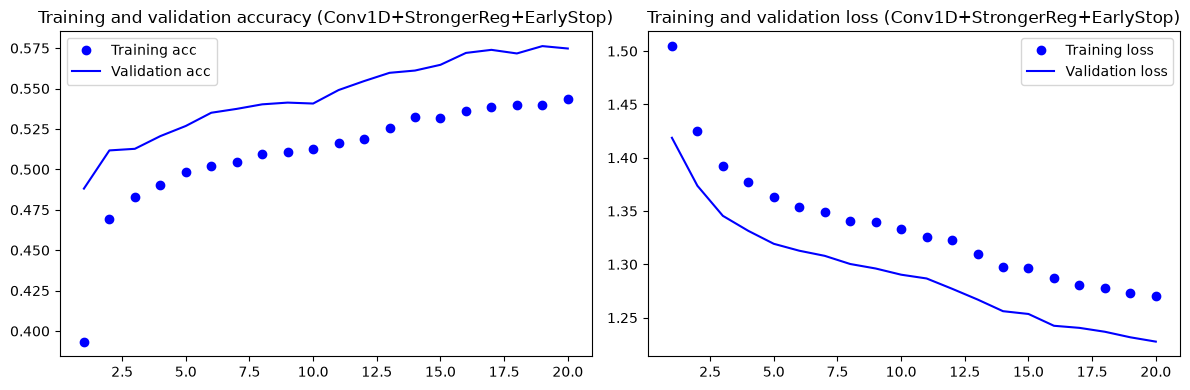

In [18]:
plot_curves(hist2c, 'Conv1D+StrongerReg+EarlyStop')

In [53]:
y_pred = np.argmax(model2c.predict(X_test), axis=1)
print("Model 1 - Attempt 2")
print(classification_report(y_true, y_pred, target_names=[f'{i+1} star' for i in range(5)]))

316/316 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Model 1 - Attempt 2
              precision    recall  f1-score   support

      1 star       0.53      0.84      0.65      3209
      2 star       0.50      0.00      0.00      1070
      3 star       0.36      0.02      0.04      1261
      4 star       0.39      0.05      0.09      1339
      5 star       0.62      0.92      0.74      3209

    accuracy                           0.57     10088
   macro avg       0.48      0.37      0.30     10088
weighted avg       0.52      0.57      0.46     10088



Model is not overfitting anymore, it just plateaued (underfit now). To combat that, add more capacity and reduce the regularisation.

### Model 1 - Attempt 3: 

In [19]:
model2d = Sequential()
model2d.add(Input(shape=(maxlen,)))
model2d.add(Embedding(max_words, 32))
model2d.add(Dropout(0.3))
model2d.add(Conv1D(32, 5, kernel_regularizer=l2(0.001), activation='relu'))
model2d.add(Conv1D(16, 3, kernel_regularizer=l2(0.001), activation='relu'))
model2d.add(GlobalAveragePooling1D())
model2d.add(Dropout(0.4))
model2d.add(Dense(5, activation='softmax'))

In [20]:
model2d.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['acc'])
model2d.summary()

early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

hist2d = model2d.fit(X_train, y_train, epochs=25, batch_size=32, validation_split=0.3, callbacks=[early_stop])

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 100, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 100, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 96, 32)         │         5,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 94, 16)         │         1,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_3      │ (None, 16)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │            85 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 326,789 (1.25 MB)

 Trainable params: 326,789 (1.25 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
883/883 ━━━━━━━━━━━━━━━━━━━━ 15s 13ms/step - acc: 0.4574 - loss: 1.4427 - val_acc: 0.5244 - val_loss: 1.3249
Epoch 2/25
883/883 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - acc: 0.5209 - loss: 1.3415 - val_acc: 0.5497 - val_loss: 1.2876
Epoch 3/25
883/883 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - acc: 0.5343 - loss: 1.3072 - val_acc: 0.5563 - val_loss: 1.2684
Epoch 4/25
883/883 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - acc: 0.5411 - loss: 1.2815 - val_acc: 0.5580 - val_loss: 1.2652
Epoch 5/25
883/883 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - acc: 0.5481 - loss: 1.2677 - val_acc: 0.5594 - val_loss: 1.2649
Epoch 6/25
883/883 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - acc: 0.5495 - loss: 1.2559 - val_acc: 0.5601 - val_loss: 1.2590
Epoch 7/25
883/883 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - acc: 0.5578 - loss: 1.2374 - val_acc: 0.5640 - val_loss: 1.2556
Epoch 8/25
883/883 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - acc: 0.5614 - loss: 1.2261 - val_acc: 0.5658 - val_loss: 1.2476
Epoch 9/25
883/883 ━━━━━━━━━━━━━━━━━━━━ 

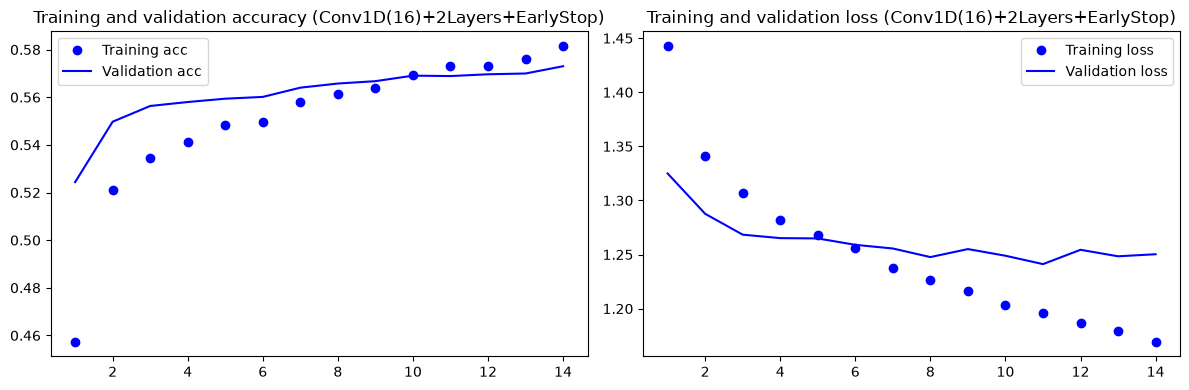

In [21]:
plot_curves(hist2d, 'Conv1D(16)+2Layers+EarlyStop')

In [54]:
y_pred = np.argmax(model2d.predict(X_test), axis=1)
print('Model 1 - Attempt 3')
print(classification_report(y_true, y_pred, target_names=[f'{i+1} star' for i in range(5)]))

316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Model 1 - Attempt 3
              precision    recall  f1-score   support

      1 star       0.53      0.83      0.65      3209
      2 star       0.50      0.00      0.00      1070
      3 star       0.29      0.03      0.05      1261
      4 star       0.35      0.06      0.10      1339
      5 star       0.62      0.91      0.73      3209

    accuracy                           0.56     10088
   macro avg       0.46      0.36      0.31     10088
weighted avg       0.50      0.56      0.46     10088



Model is mildly overfitting.

## Model 1 - Attempt 4: decrease filter to try to close the loss gap

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ (None, 100, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 100, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 96, 24)         │         3,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_6 (Conv1D)               │ (None, 94, 16)         │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_4      │ (None, 16)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 5)              │            85 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 325,117 (1.24 MB)

 Trainable params: 325,117 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
883/883 ━━━━━━━━━━━━━━━━━━━━ 15s 13ms/step - acc: 0.4132 - loss: 1.4949 - val_acc: 0.5136 - val_loss: 1.3850
Epoch 2/25
883/883 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - acc: 0.4994 - loss: 1.3901 - val_acc: 0.5346 - val_loss: 1.3254
Epoch 3/25
883/883 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - acc: 0.5179 - loss: 1.3506 - val_acc: 0.5424 - val_loss: 1.3067
Epoch 4/25
883/883 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - acc: 0.5222 - loss: 1.3330 - val_acc: 0.5487 - val_loss: 1.2886
Epoch 5/25
883/883 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - acc: 0.5291 - loss: 1.3161 - val_acc: 0.5541 - val_loss: 1.2833
Epoch 6/25
883/883 ━━━━━━━━━━━━━━━━━━━━ 13s 14ms/step - acc: 0.5352 - loss: 1.3013 - val_acc: 0.5546 - val_loss: 1.2748
Epoch 7/25
883/883 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - acc: 0.5372 - loss: 1.2933 - val_acc: 0.5572 - val_loss: 1.2775
Epoch 8/25
883/883 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - acc: 0.5402 - loss: 1.2851 - val_acc: 0.5555 - val_loss: 1.2722
Epoch 9/25
883/883 ━━━━━━━━━━━━━━━━━━━━ 

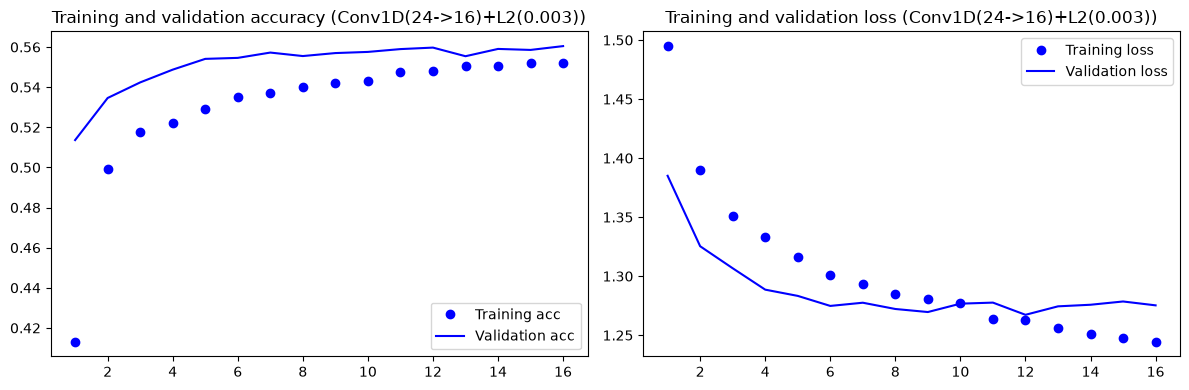

In [22]:
model2e = Sequential()
model2e.add(Input(shape=(maxlen,)))
model2e.add(Embedding(max_words, 32))
model2e.add(Dropout(0.4))
model2e.add(Conv1D(24, 5, kernel_regularizer=l2(0.003), activation='relu')) 
model2e.add(Conv1D(16, 3, kernel_regularizer=l2(0.003), activation='relu'))
model2e.add(GlobalAveragePooling1D())
model2e.add(Dropout(0.5))
model2e.add(Dense(5, activation='softmax'))

model2e.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['acc'])
model2e.summary()

early_stop = EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)

hist2e = model2e.fit(X_train, y_train, epochs=25, batch_size=32, validation_split=0.3, callbacks=[early_stop])

plot_curves(hist2e, 'Conv1D(24->16)+L2(0.003)')

In [55]:
y_pred = np.argmax(model2e.predict(X_test), axis=1)
print('Model 1 - Attempt 4')
print(classification_report(y_true, y_pred, target_names=[f'{i+1} star' for i in range(5)]))

316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Model 1 - Attempt 4
              precision    recall  f1-score   support

      1 star       0.50      0.84      0.63      3209
      2 star       0.00      0.00      0.00      1070
      3 star       0.00      0.00      0.00      1261
      4 star       0.00      0.00      0.00      1339
      5 star       0.62      0.90      0.73      3209

    accuracy                           0.55     10088
   macro avg       0.22      0.35      0.27     10088
weighted avg       0.36      0.55      0.43     10088



c:\Users\jaeth\anaconda3\envs\hw\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\jaeth\anaconda3\envs\hw\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\jaeth\anaconda3\envs\hw\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


Comparing all the attempts results.

In [23]:
print("Attempt 1 (model2b):", hist2b.history['val_acc'][-1], hist2b.history['val_loss'][-1])
print("Attempt 2 (model2c):", hist2c.history['val_acc'][-1], hist2c.history['val_loss'][-1])
print("Attempt 3 (model2d):", hist2d.history['val_acc'][-1], hist2d.history['val_loss'][-1])
print("Attempt 4 (model2e):", hist2e.history['val_acc'][-1], hist2e.history['val_loss'][-1])

Attempt 1 (model2b): 0.5825210809707642 1.1991006135940552
Attempt 2 (model2c): 0.5747563242912292 1.2275620698928833
Attempt 3 (model2d): 0.573021650314331 1.2502684593200684
Attempt 4 (model2e): 0.5604658722877502 1.2752853631973267


Attempt 1 gave the best validation accuracy and loss combination and was ultimately selected to be saved as Model 1.

In [24]:
# Save the Model
base_dir = r"C:\Users\jaeth\Downloads\NP\Y2S1\DL\DL ASG"
path1 = os.path.join(base_dir, 'text_model_1.h5')
model2b.save(path1)

## Model 2 - Functional API (GloVe + LSTM, Conv1D from scratch)

Model: "functional_30"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text (InputLayer)   │ (None, 100)       │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_6         │ (None, 100, 100)  │  1,000,000 │ text[0][0]        │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_7 (Conv1D)   │ (None, 94, 32)    │     22,432 │ embedding_6[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 31, 32)    │          0 │ conv1d_7[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_5         │ (None, 100, 200)  │  2,000,000 │ text[0][0]        │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_8 (Conv1D)   │ (None, 29, 32)    │      3,104 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 32)        │     29,824 │ embedding_5[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 32)        │          0 │ conv1d_8[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 64)        │          0 │ lstm[0][0],       │
│ (Concatenate)       │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_8 (Dropout) │ (None, 64)        │          0 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 5)         │        325 │ dropout_8[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 3,055,685 (11.66 MB)

 Trainable params: 3,055,685 (11.66 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
883/883 ━━━━━━━━━━━━━━━━━━━━ 86s 90ms/step - acc: 0.5163 - loss: 1.3113 - val_acc: 0.5829 - val_loss: 1.1652
Epoch 2/15
883/883 ━━━━━━━━━━━━━━━━━━━━ 75s 84ms/step - acc: 0.5835 - loss: 1.1622 - val_acc: 0.5908 - val_loss: 1.1432
Epoch 3/15
883/883 ━━━━━━━━━━━━━━━━━━━━ 82s 93ms/step - acc: 0.6025 - loss: 1.0991 - val_acc: 0.5928 - val_loss: 1.1416
Epoch 4/15
883/883 ━━━━━━━━━━━━━━━━━━━━ 79s 89ms/step - acc: 0.6206 - loss: 1.0391 - val_acc: 0.5891 - val_loss: 1.1657
Epoch 5/15
883/883 ━━━━━━━━━━━━━━━━━━━━ 81s 92ms/step - acc: 0.6413 - loss: 0.9792 - val_acc: 0.5788 - val_loss: 1.2023


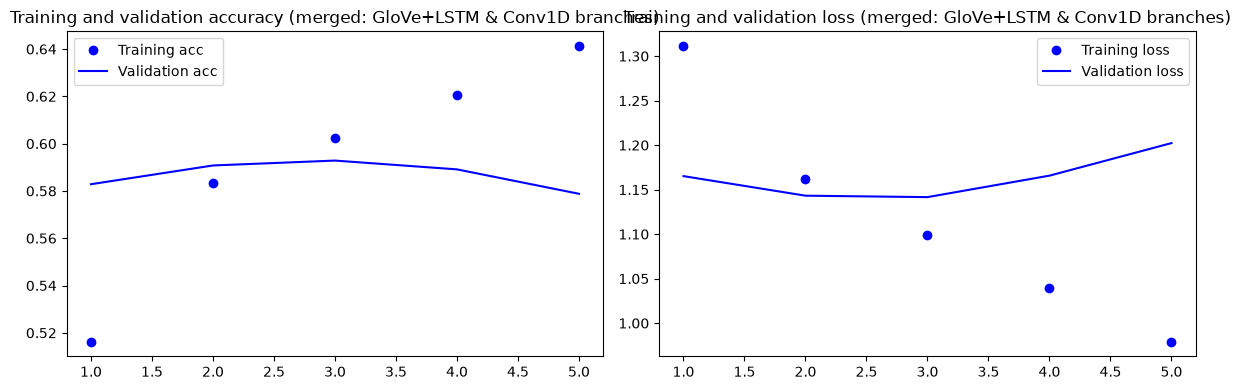

In [25]:
text_input = Input(shape=(maxlen,), name='text')

#A: GloVe + LSTM
branch_a = layers.Embedding(max_words, embedding_dim, weights=[embedding_matrix], trainable=True)(text_input)
branch_a = layers.LSTM(32, recurrent_dropout=0.3)(branch_a)

#B: Conv1D from scratch
branch_b = layers.Embedding(max_words, 100)(text_input)
branch_b = layers.Conv1D(32, 7, activation='relu')(branch_b)
branch_b = layers.MaxPooling1D(3)(branch_b)
branch_b = layers.Conv1D(32, 3, activation='relu')(branch_b)
branch_b = layers.GlobalMaxPooling1D()(branch_b)

merged = layers.concatenate([branch_a, branch_b])
merged = layers.Dropout(0.35)(merged)

output = layers.Dense(5, kernel_regularizer=l2(0.001), activation='softmax')(merged)

model_merged = Model(text_input, output)
model_merged.compile(optimizer=Adam(learning_rate=0.0005), loss='categorical_crossentropy', metrics=['acc'])

model_merged.summary()


early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)
hist_merged = model_merged.fit(X_train, y_train, epochs=15, batch_size=32, validation_split=0.3, callbacks=([early_stop]))

plot_curves(hist_merged, 'merged: GloVe+LSTM & Conv1D branches')

In [56]:
y_pred = np.argmax(model_merged.predict(X_test), axis=1)
print('Model 2 - Baseline Model')
print(classification_report(y_true, y_pred, target_names=[f'{i+1} star' for i in range(5)]))

316/316 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step
Model 2 - Baseline Model
              precision    recall  f1-score   support

      1 star       0.56      0.89      0.69      3209
      2 star       0.75      0.00      0.01      1070
      3 star       0.29      0.11      0.16      1261
      4 star       0.42      0.11      0.17      1339
      5 star       0.68      0.88      0.77      3209

    accuracy                           0.59     10088
   macro avg       0.54      0.40      0.36     10088
weighted avg       0.57      0.59      0.51     10088



OVERFITTING.

### Model 2 - Attempt 1 (shrink branch b)

Model: "functional_31"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text (InputLayer)   │ (None, 100)       │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_8         │ (None, 100, 64)   │    640,000 │ text[0][0]        │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_9 (Dropout) │ (None, 100, 64)   │          0 │ embedding_8[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_9 (Conv1D)   │ (None, 94, 32)    │     14,368 │ dropout_9[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 31, 32)    │          0 │ conv1d_9[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_7         │ (None, 100, 200)  │  2,000,000 │ text[0][0]        │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_10 (Conv1D)  │ (None, 29, 32)    │      3,104 │ max_pooling1d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ (None, 32)        │     29,824 │ embedding_7[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 32)        │          0 │ conv1d_10[0][0]   │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 64)        │          0 │ lstm_1[0][0],     │
│ (Concatenate)       │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_10          │ (None, 64)        │          0 │ concatenate_1[0]… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 5)         │        325 │ dropout_10[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,687,621 (10.25 MB)

 Trainable params: 2,687,621 (10.25 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
883/883 ━━━━━━━━━━━━━━━━━━━━ 79s 82ms/step - acc: 0.4970 - loss: 1.3530 - val_acc: 0.5673 - val_loss: 1.2124
Epoch 2/15
883/883 ━━━━━━━━━━━━━━━━━━━━ 84s 95ms/step - acc: 0.5720 - loss: 1.1986 - val_acc: 0.5862 - val_loss: 1.1538
Epoch 3/15
883/883 ━━━━━━━━━━━━━━━━━━━━ 95s 107ms/step - acc: 0.5886 - loss: 1.1398 - val_acc: 0.5876 - val_loss: 1.1495
Epoch 4/15
883/883 ━━━━━━━━━━━━━━━━━━━━ 101s 114ms/step - acc: 0.5992 - loss: 1.1048 - val_acc: 0.5907 - val_loss: 1.1455
Epoch 5/15
883/883 ━━━━━━━━━━━━━━━━━━━━ 123s 140ms/step - acc: 0.6124 - loss: 1.0664 - val_acc: 0.5912 - val_loss: 1.1566
Epoch 6/15
883/883 ━━━━━━━━━━━━━━━━━━━━ 115s 130ms/step - acc: 0.6232 - loss: 1.0337 - val_acc: 0.5857 - val_loss: 1.1775


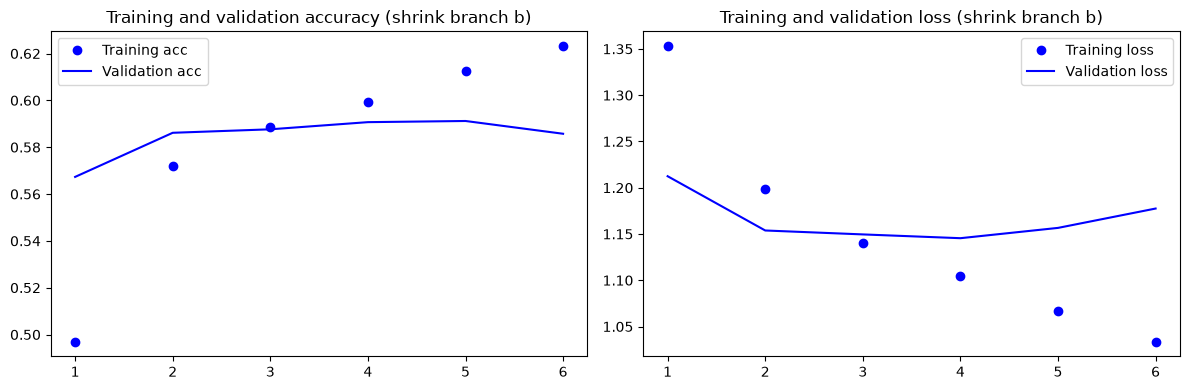

In [26]:
text_input = Input(shape=(maxlen,), name='text')

#A: GloVe + LSTM
branch_a2 = layers.Embedding(max_words, embedding_dim, weights=[embedding_matrix], trainable=True)(text_input)
branch_a2 = layers.LSTM(32, recurrent_dropout=0.3)(branch_a2)

#B: Conv1D from scratch
branch_b2 = layers.Embedding(max_words, 64)(text_input)   #reduce from 100 to 64
branch_b2 = layers.Dropout(0.3)(branch_b2)
branch_b2 = layers.Conv1D(32, 7, activation='relu')(branch_b2)
branch_b2 = layers.MaxPooling1D(3)(branch_b2)
branch_b2 = layers.Conv1D(32, 3, activation='relu')(branch_b2)
branch_b2 = layers.GlobalMaxPooling1D()(branch_b2)

merged2 = layers.concatenate([branch_a2, branch_b2])
merged2 = layers.Dropout(0.35)(merged2)

output2 = layers.Dense(5, kernel_regularizer=l2(0.001), activation='softmax')(merged2)

model_merged2 = Model(text_input, output2)
model_merged2.compile(optimizer=Adam(learning_rate=0.0005), loss='categorical_crossentropy', metrics=['acc'])

model_merged2.summary()


early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)
hist2_merged = model_merged2.fit(X_train, y_train, epochs=15, batch_size=32, validation_split=0.3, callbacks=([early_stop]))

plot_curves(hist2_merged, 'shrink branch b')

In [57]:
y_pred = np.argmax(model_merged2.predict(X_test), axis=1)
print('Model 2 - Attept 1')
print(classification_report(y_true, y_pred, target_names=[f'{i+1} star' for i in range(5)]))

316/316 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step
Model 2 - Attept 1
              precision    recall  f1-score   support

      1 star       0.57      0.87      0.69      3209
      2 star       0.00      0.00      0.00      1070
      3 star       0.31      0.11      0.17      1261
      4 star       0.42      0.09      0.14      1339
      5 star       0.65      0.90      0.76      3209

    accuracy                           0.59     10088
   macro avg       0.39      0.39      0.35     10088
weighted avg       0.48      0.59      0.50     10088



c:\Users\jaeth\anaconda3\envs\hw\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\jaeth\anaconda3\envs\hw\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\jaeth\anaconda3\envs\hw\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


## Model 2 - Attempt 2 (monitor val_acc [max] and increase patience in earlystop, increase dropout-0.4)

Model: "functional_32"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text (InputLayer)   │ (None, 100)       │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_10        │ (None, 100, 64)   │    640,000 │ text[0][0]        │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_11          │ (None, 100, 64)   │          0 │ embedding_10[0][… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_11 (Conv1D)  │ (None, 94, 32)    │     14,368 │ dropout_11[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_2     │ (None, 31, 32)    │          0 │ conv1d_11[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_9         │ (None, 100, 200)  │  2,000,000 │ text[0][0]        │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_12 (Conv1D)  │ (None, 29, 32)    │      3,104 │ max_pooling1d_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ (None, 32)        │     29,824 │ embedding_9[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 32)        │          0 │ conv1d_12[0][0]   │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 64)        │          0 │ lstm_2[0][0],     │
│ (Concatenate)       │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_12          │ (None, 64)        │          0 │ concatenate_2[0]… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 5)         │        325 │ dropout_12[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,687,621 (10.25 MB)

 Trainable params: 2,687,621 (10.25 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
883/883 ━━━━━━━━━━━━━━━━━━━━ 95s 99ms/step - acc: 0.4744 - loss: 1.3795 - val_acc: 0.5636 - val_loss: 1.2286
Epoch 2/20
883/883 ━━━━━━━━━━━━━━━━━━━━ 99s 112ms/step - acc: 0.5651 - loss: 1.2179 - val_acc: 0.5890 - val_loss: 1.1537
Epoch 3/20
883/883 ━━━━━━━━━━━━━━━━━━━━ 89s 100ms/step - acc: 0.5862 - loss: 1.1499 - val_acc: 0.5909 - val_loss: 1.1422
Epoch 4/20
883/883 ━━━━━━━━━━━━━━━━━━━━ 72s 81ms/step - acc: 0.5963 - loss: 1.1087 - val_acc: 0.5911 - val_loss: 1.1443
Epoch 5/20
883/883 ━━━━━━━━━━━━━━━━━━━━ 70s 79ms/step - acc: 0.6095 - loss: 1.0697 - val_acc: 0.5910 - val_loss: 1.1532
Epoch 6/20
883/883 ━━━━━━━━━━━━━━━━━━━━ 87s 98ms/step - acc: 0.6218 - loss: 1.0313 - val_acc: 0.5905 - val_loss: 1.1619
Epoch 7/20
883/883 ━━━━━━━━━━━━━━━━━━━━ 70s 79ms/step - acc: 0.6350 - loss: 0.9984 - val_acc: 0.5842 - val_loss: 1.1823


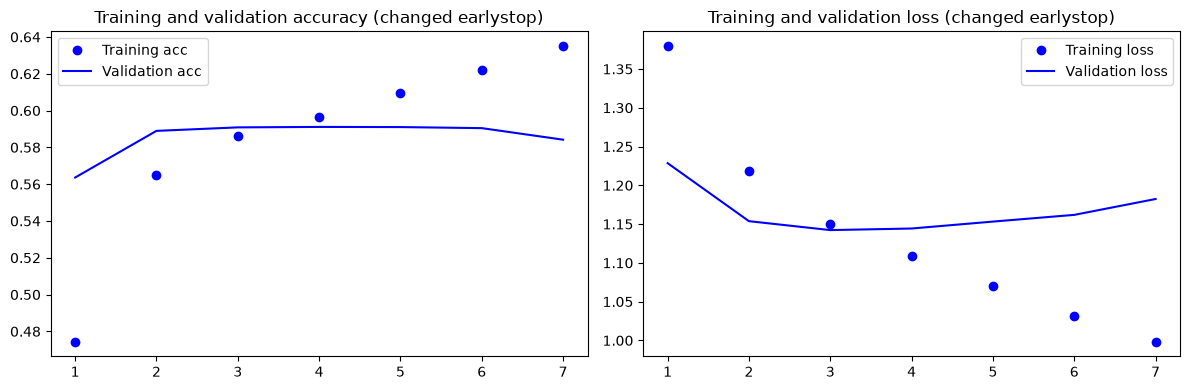

In [27]:
text_input = Input(shape=(maxlen,), name='text')

#A: GloVe + LSTM
branch_a3 = layers.Embedding(max_words, embedding_dim, weights=[embedding_matrix], trainable=True)(text_input)
branch_a3 = layers.LSTM(32, recurrent_dropout=0.3)(branch_a3)

#B: Conv1D from scratch
branch_b3 = layers.Embedding(max_words, 64)(text_input)  
branch_b3 = layers.Dropout(0.3)(branch_b3)
branch_b3 = layers.Conv1D(32, 7, activation='relu')(branch_b3)
branch_b3 = layers.MaxPooling1D(3)(branch_b3)
branch_b3 = layers.Conv1D(32, 3, activation='relu')(branch_b3)
branch_b3 = layers.GlobalMaxPooling1D()(branch_b3)

merged3 = layers.concatenate([branch_a3, branch_b3])
merged3 = layers.Dropout(0.4)(merged3)

output3 = layers.Dense(5, kernel_regularizer=l2(0.001), activation='softmax')(merged3)

model_merged3 = Model(text_input, output3)
model_merged3.compile(optimizer=Adam(learning_rate=0.0005), loss='categorical_crossentropy', metrics=['acc'])

model_merged3.summary()

early_stop = EarlyStopping(monitor='val_acc', mode='max', patience=3, restore_best_weights=True)
hist3_merged = model_merged3.fit(X_train, y_train, epochs=20, batch_size=32, validation_split=0.3, callbacks=([early_stop]))

plot_curves(hist3_merged, 'changed earlystop')

In [60]:
y_pred = np.argmax(model_merged3.predict(X_test), axis=1)
print('Model 2 - Attempt 2')
print(classification_report(y_true, y_pred, target_names=[f'{i+1} star' for i in range(5)]))

316/316 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step
Model 2 - Attempt 2
              precision    recall  f1-score   support

      1 star       0.57      0.87      0.68      3209
      2 star       0.00      0.00      0.00      1070
      3 star       0.29      0.15      0.19      1261
      4 star       0.43      0.09      0.14      1339
      5 star       0.67      0.89      0.77      3209

    accuracy                           0.59     10088
   macro avg       0.39      0.40      0.36     10088
weighted avg       0.49      0.59      0.50     10088



## Model 2 - Attempt 3 (trainable=False. dropout back to 0.35)

Model: "functional_33"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text (InputLayer)   │ (None, 100)       │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_12        │ (None, 100, 64)   │    640,000 │ text[0][0]        │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_13          │ (None, 100, 64)   │          0 │ embedding_12[0][… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_13 (Conv1D)  │ (None, 94, 32)    │     14,368 │ dropout_13[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_3     │ (None, 31, 32)    │          0 │ conv1d_13[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_11        │ (None, 100, 200)  │  2,000,000 │ text[0][0]        │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_14 (Conv1D)  │ (None, 29, 32)    │      3,104 │ max_pooling1d_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_3 (LSTM)       │ (None, 32)        │     29,824 │ embedding_11[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 32)        │          0 │ conv1d_14[0][0]   │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_3       │ (None, 64)        │          0 │ lstm_3[0][0],     │
│ (Concatenate)       │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_14          │ (None, 64)        │          0 │ concatenate_3[0]… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 5)         │        325 │ dropout_14[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,687,621 (10.25 MB)

 Trainable params: 687,621 (2.62 MB)

 Non-trainable params: 2,000,000 (7.63 MB)

Epoch 1/20
883/883 ━━━━━━━━━━━━━━━━━━━━ 64s 66ms/step - acc: 0.4996 - loss: 1.3562 - val_acc: 0.5701 - val_loss: 1.2040
Epoch 2/20
883/883 ━━━━━━━━━━━━━━━━━━━━ 59s 66ms/step - acc: 0.5744 - loss: 1.1924 - val_acc: 0.5899 - val_loss: 1.1470
Epoch 3/20
883/883 ━━━━━━━━━━━━━━━━━━━━ 59s 66ms/step - acc: 0.5923 - loss: 1.1324 - val_acc: 0.5945 - val_loss: 1.1414
Epoch 4/20
883/883 ━━━━━━━━━━━━━━━━━━━━ 58s 66ms/step - acc: 0.6042 - loss: 1.0940 - val_acc: 0.5925 - val_loss: 1.1364
Epoch 5/20
883/883 ━━━━━━━━━━━━━━━━━━━━ 63s 71ms/step - acc: 0.6167 - loss: 1.0529 - val_acc: 0.5922 - val_loss: 1.1519
Epoch 6/20
883/883 ━━━━━━━━━━━━━━━━━━━━ 58s 66ms/step - acc: 0.6280 - loss: 1.0186 - val_acc: 0.5841 - val_loss: 1.1672


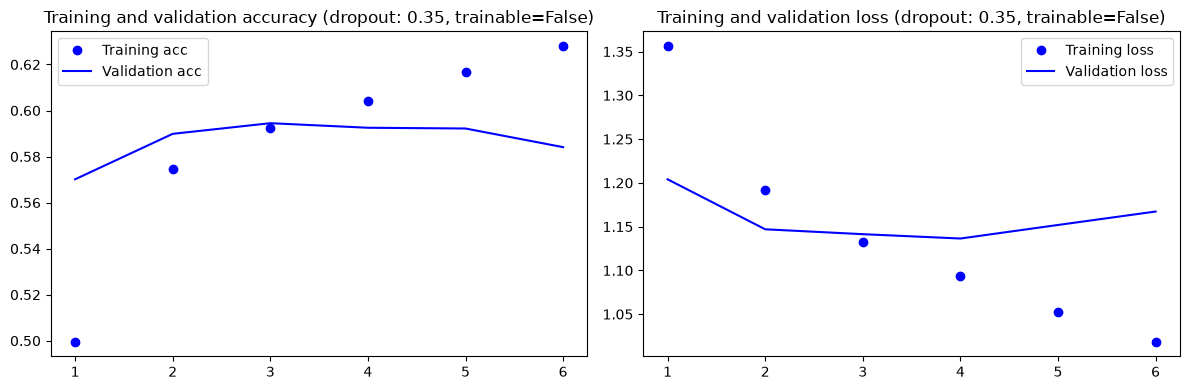

In [28]:
text_input = Input(shape=(maxlen,), name='text')

#A: GloVe + LSTM
branch_a4 = layers.Embedding(max_words, embedding_dim, weights=[embedding_matrix], trainable=False)(text_input)
branch_a4 = layers.LSTM(32, recurrent_dropout=0.3)(branch_a4)

#B: Conv1D from scratch
branch_b4 = layers.Embedding(max_words, 64)(text_input)  
branch_b4 = layers.Dropout(0.3)(branch_b4)
branch_b4 = layers.Conv1D(32, 7, activation='relu')(branch_b4)
branch_b4 = layers.MaxPooling1D(3)(branch_b4)
branch_b4 = layers.Conv1D(32, 3, activation='relu')(branch_b4)
branch_b4 = layers.GlobalMaxPooling1D()(branch_b4)

merged4 = layers.concatenate([branch_a4, branch_b4])
merged4 = layers.Dropout(0.35)(merged4)

output4 = layers.Dense(5, kernel_regularizer=l2(0.001), activation='softmax')(merged4)

model_merged4 = Model(text_input, output4)
model_merged4.compile(optimizer=Adam(learning_rate=0.0005), loss='categorical_crossentropy', metrics=['acc'])

model_merged4.summary()

early_stop = EarlyStopping(monitor='val_acc', mode='max', patience=3, restore_best_weights=True)
hist4_merged = model_merged4.fit(X_train, y_train, epochs=20, batch_size=32, validation_split=0.3, callbacks=([early_stop]))

plot_curves(hist4_merged, 'dropout: 0.35, trainable=False')

In [59]:
y_pred = np.argmax(model_merged4.predict(X_test), axis=1)
print('Model 2 - Attempt 3')
print(classification_report(y_true, y_pred, target_names=[f'{i+1} star' for i in range(5)]))

316/316 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step
Model 2 - Attempt 3
              precision    recall  f1-score   support

      1 star       0.55      0.89      0.68      3209
      2 star       0.00      0.00      0.00      1070
      3 star       0.35      0.08      0.13      1261
      4 star       0.41      0.11      0.17      1339
      5 star       0.67      0.89      0.77      3209

    accuracy                           0.59     10088
   macro avg       0.40      0.39      0.35     10088
weighted avg       0.49      0.59      0.50     10088



c:\Users\jaeth\anaconda3\envs\hw\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\jaeth\anaconda3\envs\hw\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\jaeth\anaconda3\envs\hw\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


## Model 2 - Attempt 4 (2 phased training)

Epoch 1/10
883/883 ━━━━━━━━━━━━━━━━━━━━ 34s 34ms/step - acc: 0.4879 - loss: 1.3701 - val_acc: 0.5616 - val_loss: 1.2291
Epoch 2/10
883/883 ━━━━━━━━━━━━━━━━━━━━ 28s 32ms/step - acc: 0.5635 - loss: 1.2216 - val_acc: 0.5814 - val_loss: 1.1593
Epoch 3/10
883/883 ━━━━━━━━━━━━━━━━━━━━ 38s 43ms/step - acc: 0.5855 - loss: 1.1474 - val_acc: 0.5902 - val_loss: 1.1403
Epoch 4/10
883/883 ━━━━━━━━━━━━━━━━━━━━ 57s 65ms/step - acc: 0.6008 - loss: 1.0960 - val_acc: 0.5909 - val_loss: 1.1391
Epoch 5/10
883/883 ━━━━━━━━━━━━━━━━━━━━ 58s 65ms/step - acc: 0.6127 - loss: 1.0551 - val_acc: 0.5918 - val_loss: 1.1461
Epoch 6/10
883/883 ━━━━━━━━━━━━━━━━━━━━ 83s 94ms/step - acc: 0.6250 - loss: 1.0200 - val_acc: 0.5824 - val_loss: 1.1663
Epoch 7/10
883/883 ━━━━━━━━━━━━━━━━━━━━ 256s 290ms/step - acc: 0.6406 - loss: 0.9834 - val_acc: 0.5767 - val_loss: 1.1942
Epoch 8/10
883/883 ━━━━━━━━━━━━━━━━━━━━ 355s 403ms/step - acc: 0.6482 - loss: 0.9472 - val_acc: 0.5653 - val_loss: 1.2312
Epoch 1/10
883/883 ━━━━━━━━━━━━━━━━━

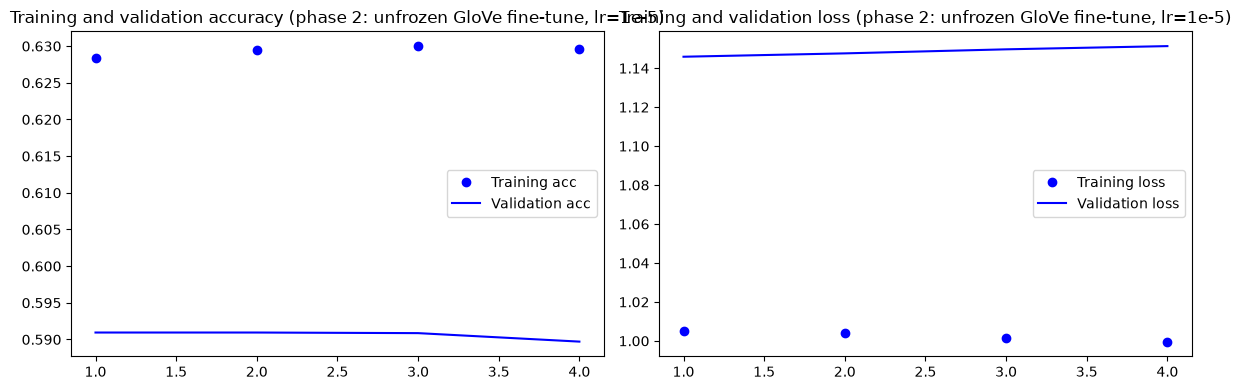

In [29]:
#A: GloVe + LSTM
branch_a5 = layers.Embedding(max_words, embedding_dim, weights=[embedding_matrix], trainable=False, name='glove_embed')(text_input)
branch_a5 = layers.LSTM(32, recurrent_dropout=0.3)(branch_a5)

#B: Conv1D from scratch
branch_b5 = layers.Embedding(max_words, 64)(text_input)  
branch_b5 = layers.Dropout(0.3)(branch_b5)
branch_b5 = layers.Conv1D(32, 7, activation='relu')(branch_b5)
branch_b5 = layers.MaxPooling1D(3)(branch_b5)
branch_b5 = layers.Conv1D(32, 3, activation='relu')(branch_b5)
branch_b5 = layers.GlobalMaxPooling1D()(branch_b5)

merged5 = layers.concatenate([branch_a5, branch_b5])
merged5 = layers.Dropout(0.35)(merged5)

output5 = layers.Dense(5, kernel_regularizer=l2(0.001), activation='softmax')(merged5)

model_merged5 = Model(text_input, output5)
model_merged5.compile(optimizer=Adam(learning_rate=0.0005), loss='categorical_crossentropy', metrics=['acc'])

early_stop = EarlyStopping(monitor='val_acc', mode='max', patience=3, restore_best_weights=True)
hist5_phase1 = model_merged5.fit(X_train, y_train, epochs=10, batch_size=32, validation_split=0.3, callbacks=[early_stop])

# Phase 2: unfreeze GloVe, fine-tune at a much lower LR
model_merged5.get_layer('glove_embed').trainable = True
model_merged5.compile(optimizer=Adam(learning_rate=1e-5), loss='categorical_crossentropy', metrics=['acc'])

early_stop2 = EarlyStopping(monitor='val_acc', mode='max', patience=3, restore_best_weights=True)
hist5_phase2 = model_merged5.fit(X_train, y_train, epochs=10, batch_size=32, validation_split=0.3, callbacks=[early_stop2])

plot_curves(hist5_phase2, 'phase 2: unfrozen GloVe fine-tune, lr=1e-5')

In [61]:
y_pred = np.argmax(model_merged5.predict(X_test), axis=1)
print('Model 2 - Attempt 4')
print(classification_report(y_true, y_pred, target_names=[f'{i+1} star' for i in range(5)]))

316/316 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step
Model 2 - Attempt 4
              precision    recall  f1-score   support

      1 star       0.58      0.84      0.68      3209
      2 star       0.10      0.00      0.00      1070
      3 star       0.28      0.15      0.20      1261
      4 star       0.37      0.12      0.18      1339
      5 star       0.66      0.89      0.76      3209

    accuracy                           0.59     10088
   macro avg       0.40      0.40      0.36     10088
weighted avg       0.49      0.59      0.51     10088



Compare results.

In [30]:
print("Shrink branch_b:", max(hist2_merged.history['val_acc']))  
print("Frozen (model4):", max(hist4_merged.history['val_acc']))
print("Two-phase (model5):", max(hist5_phase1.history['val_acc']), max(hist5_phase2.history['val_acc']))

Shrink branch_b: 0.5911944508552551
Frozen (model4): 0.5944985747337341
Two-phase (model5): 0.5917726755142212 0.590946614742279


In [31]:
# Save the Model
path2 = os.path.join(base_dir, 'text_model_2.h5')
model_merged4.save(path2)

## Step 3 – Evaluate the Model using Testing Data

In [32]:
# Model #1 (replicate where necessary for other models)
model1 = keras.models.load_model('text_model_1.h5')

test_loss1, test_acc1 = model1.evaluate(X_test, y_test)
print(f'model 1 - test loss: {test_loss1:.4f}, test acc: {test_acc1:.4f}')


316/316 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - acc: 0.5786 - loss: 1.2107
model 1 - test loss: 1.2107, test acc: 0.5786


In [43]:
# Model #2 (replicate where necessary for other models)
model2 = keras.models.load_model('text_model_2.h5')

test_loss2, test_acc2 = model2.evaluate(X_test, y_test)
print(f'model 2 - test loss: {test_loss2:.4f}, test acc: {test_acc2:.4f}')


316/316 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - acc: 0.5918 - loss: 1.1457
model 2 - test loss: 1.1457, test acc: 0.5918


In [34]:
# Save the Best Model
model2.save('text_model_best.h5')

## Step 4 – Use the Best Model to make prediction

In [35]:
best_model = keras.models.load_model('text_model_best.h5')

In [36]:
# takes the user input
user_input = input('Enter review: ')  # "tiktok is really good. its very engaging. i can spend hours on the app without feeling bored.""

In [37]:
# convert the user input into numeric tensor
cleaned = clean(user_input)          # reuse same clean() function from step 1.2
input_tensor = vectorizer([cleaned]) # reuse SAME vectorizer object 
input_tensor = np.array(input_tensor)

In [38]:
# show the model output using predict function

pred = best_model.predict(input_tensor)
predicted_class = np.argmax(pred, axis=1)[0] + 1   # +1 to convert back from 0-4 to 1-5 star scale

print(f"Predicted sentiment score: {predicted_class} star(s)")
print(f"Class probabilities: {pred[0]}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step   
Predicted sentiment score: 5 star(s)
Class probabilities: [0.00888262 0.00916225 0.04016472 0.17352322 0.7682673 ]


Predict on a very bad review.

In [39]:
user_input = input('Enter input: ') 
#Wow this app is horrible. It keeps lagging and accidentally refreshing. 
#It also keeps giving me ads now. It was so much better before they shoved ads in my face every 5s

cleaned = clean(user_input)
input_tensor = vectorizer([cleaned])
input_tensor = np.array(input_tensor)

pred = best_model.predict(input_tensor)
predicted_class = np.argmax(pred, axis=1)[0]+1

print(f"Predicted sentiment score: {predicted_class} star(s)")
print(f"Class probabilities: {pred[0]}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
Predicted sentiment score: 1 star(s)
Class probabilities: [8.4233004e-01 9.3407102e-02 5.6403417e-02 7.7407337e-03 1.1878563e-04]


Predict on another review - good but some negative so hopefully its predicts 3 (middle ground)

In [40]:
user_input = input('Enter input: ') 
#it was such a good app but i recently had trouble logging in, 
#and it restarted my algorithm so now i kind of have to rebuild it back up again. but other than that, the app has been great.

cleaned = clean(user_input)
input_tensor = vectorizer([cleaned])
input_tensor = np.array(input_tensor)

pred = best_model.predict(input_tensor)
predicted_class = np.argmax(pred, axis=1)[0]+1

print(f"Predicted sentiment score: {predicted_class} star(s)")
print(f"Class probabilities: {pred[0]}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step
Predicted sentiment score: 1 star(s)
Class probabilities: [0.40793687 0.16556957 0.272429   0.13990836 0.01415624]


<hr>

# Best model performance on group mates' data. 

In [62]:
def eval_on_team_data(path, model, vectorizer, maxlen=150):
    data = pd.read_csv(path)
    data = data.dropna(subset=['content']).reset_index(drop=True)
    data['clean_content'] = data['content'].astype(str).apply(clean)

    texts = data['clean_content'].to_list()
    scores = data['score'].values

    X_new = vectorizer(texts)
    X_new = np.array(X_new)
    y_new = to_categorical(scores-1, num_classes=5)

    loss, acc = model.evaluate(X_new, y_new)
    print(f'{path} - test loss: {loss:.4f}, test acc: {acc:.4f}')

    y_pred = np.argmax(model.predict(X_new), axis=1)
    y_true = np.argmax(y_new, axis=1)
    print(classification_report(y_true, y_pred, target_names=[f'{i+1} star' for i in range(5)]))

    return loss, acc

In [ ]:
eval_on_team_data(r"./telegram.csv", best_model, vectorizer)
eval_on_team_data(r"./spotify_reviews.csv", best_model, vectorizer)
eval_on_team_data(r"./netflix_reviews.csv", best_model, vectorizer)
# keeping this for a more organized view of the results

6256/6256 ━━━━━━━━━━━━━━━━━━━━ 227s 36ms/step - acc: 0.7432 - loss: 0.9251
./telegram.csv - test loss: 0.9251, test acc: 0.7432
3132/3132 ━━━━━━━━━━━━━━━━━━━━ 106s 34ms/step - acc: 0.6970 - loss: 0.9769
./spotify_reviews.csv - test loss: 0.9769, test acc: 0.6970
3131/3131 ━━━━━━━━━━━━━━━━━━━━ 114s 36ms/step - acc: 0.7171 - loss: 0.9475
./netflix_reviews.csv - test loss: 0.9475, test acc: 0.7171


(0.9475210309028625, 0.7170803546905518)

In [63]:
eval_on_team_data(r"./telegram.csv", best_model, vectorizer)
eval_on_team_data(r"./spotify_reviews.csv", best_model, vectorizer)
eval_on_team_data(r"./netflix_reviews.csv", best_model, vectorizer)

6256/6256 ━━━━━━━━━━━━━━━━━━━━ 72s 11ms/step - acc: 0.7432 - loss: 0.9251
./telegram.csv - test loss: 0.9251, test acc: 0.7432
6256/6256 ━━━━━━━━━━━━━━━━━━━━ 69s 11ms/step


c:\Users\jaeth\anaconda3\envs\hw\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\jaeth\anaconda3\envs\hw\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\jaeth\anaconda3\envs\hw\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


              precision    recall  f1-score   support

      1 star       0.74      0.84      0.78     79082
      2 star       0.00      0.00      0.00      8426
      3 star       0.19      0.03      0.06      8141
      4 star       0.16      0.04      0.06     10602
      5 star       0.77      0.87      0.82     93930

    accuracy                           0.74    200181
   macro avg       0.37      0.36      0.34    200181
weighted avg       0.67      0.74      0.70    200181

3132/3132 ━━━━━━━━━━━━━━━━━━━━ 40s 13ms/step - acc: 0.6970 - loss: 0.9769
./spotify_reviews.csv - test loss: 0.9769, test acc: 0.6970
3132/3132 ━━━━━━━━━━━━━━━━━━━━ 37s 12ms/step


c:\Users\jaeth\anaconda3\envs\hw\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\jaeth\anaconda3\envs\hw\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\jaeth\anaconda3\envs\hw\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


              precision    recall  f1-score   support

      1 star       0.54      0.88      0.67     22907
      2 star       0.00      0.00      0.00      5055
      3 star       0.20      0.08      0.11      5674
      4 star       0.29      0.14      0.19      9625
      5 star       0.85      0.84      0.85     56937

    accuracy                           0.70    100198
   macro avg       0.38      0.39      0.36    100198
weighted avg       0.65      0.70      0.66    100198

3131/3131 ━━━━━━━━━━━━━━━━━━━━ 41s 13ms/step - acc: 0.7171 - loss: 0.9475
./netflix_reviews.csv - test loss: 0.9475, test acc: 0.7171
3131/3131 ━━━━━━━━━━━━━━━━━━━━ 38s 12ms/step
              precision    recall  f1-score   support

      1 star       0.71      0.88      0.79     41700
      2 star       0.00      0.00      0.00      5963
      3 star       0.22      0.05      0.08      5711
      4 star       0.22      0.09      0.13      6550
      5 star       0.77      0.85      0.81     40267

    ac

c:\Users\jaeth\anaconda3\envs\hw\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\jaeth\anaconda3\envs\hw\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\jaeth\anaconda3\envs\hw\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


(0.9475210309028625, 0.7170803546905518)